<a href="https://colab.research.google.com/github/mihirgohil1402-ui/Cfd-lab/blob/main/10_Turbulent_Pipe_Flow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 10: Turbulent Pipe Flow

**Name:** Mihir Gohil  |  **Roll No:** 23BME019  
**Course:** Computational Fluid Dynamics and Heat Transfer Lab (20ME406P), Department of Mechanical Engineering, PDEU


## 1. Aim
To solve for the mean velocity profile of fully developed turbulent pipe flow with the finite volume method using two mixing-length closures (Prandtl and van Driest), to verify the solver against an exact laminar solution and the exact total-stress distribution, and to study the effect of near-wall damping on the profile, the bulk velocity and the friction factor.

## 2. Problem and parameters
Air-like fluid in a straight smooth pipe. The flow is statistically steady, fully developed and axisymmetric, driven by a uniform pressure gradient. The pressure gradient is set through the friction velocity, so the bulk velocity and Reynolds number are results.

| Parameter | Symbol | Value |
|---|---|---|
| Pipe radius | R | 0.025 m |
| Kinematic viscosity | ν | 1.5 × 10⁻⁵ m²/s |
| Density | ρ | 1.2 kg/m³ |
| Friction velocity (main case) | u_τ | 0.20 m/s (Re_τ = u_τ R/ν = 333) |
| Other u_τ for the parametric study | | 0.10, 0.40 m/s |
| von Kármán constant | κ | 0.41 |
| van Driest constant | A⁺ | 26 |
| Cells | N | 200, stretched towards the wall |

## 3. Governing equation and method
Reynolds-averaged momentum equation for fully developed flow, with the Boussinesq eddy viscosity:
$$\frac{1}{r}\frac{d}{dr}\left[r(\nu+\nu_t)\frac{du}{dr}\right] = -G, \qquad G = -\frac{1}{\rho}\frac{dp}{dx} = \frac{2u_\tau^2}{R}$$
so the total shear stress is exactly τ/ρ = (ν + ν_t) du/dr = u_τ² r/R.

**Mixing-length closures,** ν_t = ℓ² |du/dr|, with y = R − r the distance from the wall:
- **Prandtl:** ℓ = κ y
- **van Driest:** ℓ = κ y [1 − exp(−y⁺/A⁺)], y⁺ = y u_τ/ν

**Finite volume discretisation.** Annular cells between faces r_f, with cell volume (r_{i+1}² − r_i²)/2 per radian. The face flux is r_f ν_eff Δu/Δr. Symmetry at the axis (zero flux) and no-slip at the wall (half-cell distance, ν_t = 0). Since ν_t depends on the solution, the system is solved by Picard iteration with under-relaxation until the profile stops changing.

**Verification.** (1) With ν_t = 0 the solver must reproduce the exact laminar Poiseuille profile u = G(R² − r²)/(4ν). (2) The computed (ν + ν_t) du/dr must equal u_τ² r/R at every face.

In [1]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import brentq

R, nu, rho = 0.025, 1.5e-5, 1.2
kappa, Aplus = 0.41, 26.0

def mesh(N=200, beta=2.5):
    xi = np.linspace(0, 1, N+1)
    y_f = R*(1 - np.tanh(beta*(1-xi))/np.tanh(beta))     # distance from the wall, fine near y = 0
    r_f = R - y_f[::-1]                                  # radial face positions, axis -> wall
    r_c = 0.5*(r_f[1:] + r_f[:-1])
    V = 0.5*(r_f[1:]**2 - r_f[:-1]**2)
    return r_f, r_c, V

def solve_pipe(u_tau, closure, N=200, tol=1e-10, relax=0.5, max_iter=500):
    r_f, r_c, V = mesh(N)
    G = 2*u_tau**2/R
    y_f = R - r_f
    # mixing length at the faces
    if closure == 'laminar':
        ell = np.zeros_like(r_f)
    else:
        ell = kappa*y_f
        if closure == 'vandriest':
            ell = ell*(1 - np.exp(-y_f*u_tau/nu/Aplus))
    nu_eff = nu*np.ones(N+1)
    u = np.zeros(N)
    for it in range(max_iter):
        # coefficients on interior faces and the wall face
        a = np.zeros(N+1)
        a[1:N] = r_f[1:N]*nu_eff[1:N]/(r_c[1:] - r_c[:-1])
        a[N] = r_f[N]*nu/(R - r_c[-1])
        diag = -(a[:-1] + a[1:])
        lower = a[1:N]            # coupling of cell i to i-1  (a_i, i = 1..N-1)
        upper = a[1:N]            # coupling of cell i to i+1
        A = sp.diags([lower, diag, upper], [-1, 0, 1], format='csc')
        u_new = spla.spsolve(A, -G*V)
        du = np.zeros(N+1)
        du[1:N] = (u_new[1:] - u_new[:-1])/(r_c[1:] - r_c[:-1])     # du/dr on interior faces (negative)
        du[N] = (0 - u_new[-1])/(R - r_c[-1])
        nu_t = ell**2*np.abs(du)
        nu_new = nu + nu_t
        change = np.max(abs(u_new - u))/np.max(abs(u_new))
        nu_eff = relax*nu_new + (1-relax)*nu_eff
        u = u_new
        if change < tol:
            break
    # final diagnostics with the converged field
    du = np.zeros(N+1)
    du[1:N] = (u[1:] - u[:-1])/(r_c[1:] - r_c[:-1]); du[N] = (0 - u[-1])/(R - r_c[-1])
    nu_t = ell**2*np.abs(du)
    stress = (nu + nu_t)*np.abs(du)
    stress_exact = u_tau**2*r_f/R
    Ub = np.sum(u*2*V)/R**2
    Reb = Ub*2*R/nu
    f = 8*u_tau**2/Ub**2
    return dict(r_f=r_f, r_c=r_c, u=u, nu_t=nu_t, stress=stress, stress_exact=stress_exact,
                Ub=Ub, Reb=Reb, f=f, Uc=u[0], iters=it+1, u_tau=u_tau)

## 4. Verification

In [2]:
# (1) Laminar test: nu_t = 0 must give Poiseuille flow exactly (up to discretisation error)
lam = solve_pipe(0.05, 'laminar')
G = 2*0.05**2/R
u_poiseuille = G*(R**2 - lam['r_c']**2)/(4*nu)
print(f"Laminar test (u_tau = 0.05): max relative error vs Poiseuille = {np.max(abs(lam['u']-u_poiseuille))/u_poiseuille.max():.2e}")
print(f"  bulk velocity numerical = {lam['Ub']:.5f} m/s, exact = {G*R**2/(8*nu):.5f} m/s, Re_b = {lam['Reb']:.0f}")

# (2) Total-stress check for the turbulent cases
pr = solve_pipe(0.20, 'prandtl'); vd = solve_pipe(0.20, 'vandriest')
for name, s in (('Prandtl', pr), ('van Driest', vd)):
    err = np.max(abs(s['stress'][1:-1] - s['stress_exact'][1:-1])/s['stress_exact'][1:-1])
    print(f"Total stress check, {name}: max relative error = {err:.2e} (iterations: {s['iters']})")

Laminar test (u_tau = 0.05): max relative error vs Poiseuille = 4.01e-05
  bulk velocity numerical = 1.04172 m/s, exact = 1.04167 m/s, Re_b = 3472
Total stress check, Prandtl: max relative error = 9.15e-10 (iterations: 25)
Total stress check, van Driest: max relative error = 4.44e-10 (iterations: 26)


## 5. Main case: u_τ = 0.20 m/s

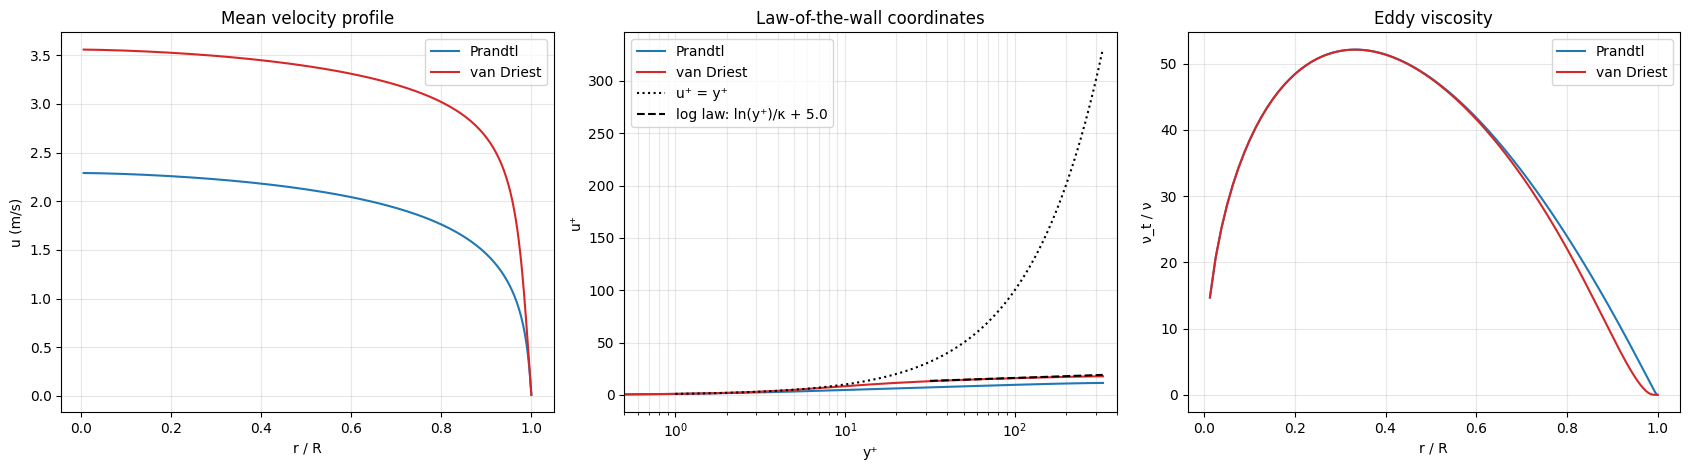

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for s, lab, col in ((pr, 'Prandtl', 'tab:blue'), (vd, 'van Driest', 'tab:red')):
    ax[0].plot(s['r_c']/R, s['u'], color=col, label=lab)
    ax[2].plot(s['r_f'][1:]/R, s['nu_t'][1:]/nu, color=col, label=lab)
    yp = (R - s['r_c'])*s['u_tau']/nu
    ax[1].semilogx(yp, s['u']/s['u_tau'], color=col, label=lab)
ypp = np.logspace(0, np.log10(330), 100)
ax[1].semilogx(ypp, ypp, 'k:', label='u⁺ = y⁺')
ax[1].semilogx(ypp[ypp > 30], np.log(ypp[ypp > 30])/kappa + 5.0, 'k--', label='log law: ln(y⁺)/κ + 5.0')
ax[0].set(xlabel='r / R', ylabel='u (m/s)', title='Mean velocity profile'); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].set(xlabel='y⁺', ylabel='u⁺', title='Law-of-the-wall coordinates', xlim=(0.5, 400)); ax[1].legend(); ax[1].grid(alpha=0.3, which='both')
ax[2].set(xlabel='r / R', ylabel='ν_t / ν', title='Eddy viscosity'); ax[2].legend(); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. Bulk quantities and effect of Reynolds number

In [4]:
rows = []
for ut in (0.10, 0.20, 0.40):
    for clo in ('prandtl', 'vandriest'):
        s = solve_pipe(ut, clo)
        # reference friction factors at the computed Reb
        blasius = 0.3164*s['Reb']**-0.25
        g = lambda f: 1/np.sqrt(f) - (2*np.log10(s['Reb']*np.sqrt(f)) - 0.8)
        f_pk = brentq(g, 1e-4, 1.0)
        rows.append([ut, ut*R/nu, clo, s['Ub'], s['Reb'], s['Uc'], s['f'], blasius, f_pk])
table = pd.DataFrame(rows, columns=['u_tau (m/s)', 'Re_tau', 'closure', 'U_bulk (m/s)', 'Re_bulk', 'U_centre (m/s)', 'f (computed)', 'f (Blasius)', 'f (Prandtl smooth-pipe law)'])
table

,u_tau (m/s),Re_tau,closure,U_bulk (m/s),Re_bulk,U_centre (m/s),f (computed),f (Blasius),f (Prandtl smooth-pipe law)
0,0.1,166.666667,prandtl,0.734357,2447.857744,0.977586,0.148346,0.044982,0.046371
1,0.1,166.666667,vandriest,1.268748,4229.160833,1.593647,0.049698,0.039235,0.039266
2,0.2,333.333333,prandtl,1.789810,5966.033355,2.290666,0.099893,0.036001,0.035567
3,0.2,333.333333,vandriest,2.968327,9894.423935,3.558398,0.036318,0.031724,0.030976
4,0.4,666.666667,prandtl,4.236553,14121.844898,5.255126,0.071316,0.029024,0.028240
5,0.4,666.666667,vandriest,6.713515,22378.381703,7.825170,0.028399,0.025869,0.025188


## 7. Effect of near-wall damping (u_τ = 0.20)

In [5]:
d = pd.DataFrame({
    'quantity': ['U_bulk (m/s)', 'U_centre (m/s)', 'Re_bulk', 'Darcy f', 'u⁺ at the centreline'],
    'Prandtl': [pr['Ub'], pr['Uc'], pr['Reb'], pr['f'], pr['Uc']/0.20],
    'van Driest': [vd['Ub'], vd['Uc'], vd['Reb'], vd['f'], vd['Uc']/0.20]})
d['difference (%)'] = 100*(d['van Driest'] - d['Prandtl'])/d['Prandtl']
d

,quantity,Prandtl,van Driest,difference (%)
0,U_bulk (m/s),1.789810,2.968327,65.845937
1,U_centre (m/s),2.290666,3.558398,55.343399
2,Re_bulk,5966.033355,9894.423935,65.845937
3,Darcy f,0.099893,0.036318,-63.642809
4,u⁺ at the centreline,11.453329,17.791991,55.343399
